<a href="https://colab.research.google.com/github/erickcorrea3092/disulfiram-metabolites-QSAR/blob/main/3_Jeff_similitud.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#ANTECEDENTES

Primero instalamos la libreria RDKit

In [1]:
import sys
import numpy as np

print("Python:", sys.version)
print("NumPy:", np.__version__)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy: 2.1.3


In [2]:
import scipy
import sklearn

print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)

print("NUMPY + SCIPY + SKLEARN OK")

SciPy: 1.16.3
Scikit-learn: 1.6.1
NUMPY + SCIPY + SKLEARN OK


In [3]:
try:
    import umap
    print("UMAP:", umap.__version__)
    print("UMAP OK")
except Exception as e:
    print("ERROR UMAP:")
    print(type(e).__name__, e)

UMAP: 0.5.12
UMAP OK


In [4]:
# from IPython.utils import io
# import tqdm.notebook
# import os, os.path, sys, random, subprocess
# total = 100
# with tqdm.notebook.tqdm(total=total) as pbar:
#     with io.capture_output() as captured:
#       pbar.update(0)
#       !pip install --upgrade --force-reinstall numpy
#       pbar.update(33)
#       !pip install --upgrade --force-reinstall pandas
#       pbar.update(66)
#       !pip install --upgrade --force-reinstall mordred
#       pbar.update(100)

# Librerias

In [5]:
from IPython.utils import io
import tqdm.notebook
import os, os.path, sys, random, subprocess
total = 100
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      !pip install molplotly
      !pip install rdkit
      !pip install mordredcommunity #__________________
      import pandas as pd
      import numpy as np
      import seaborn as sn
      #---------------------- RDKit packages
      from rdkit.Chem import AllChem
      from rdkit.Chem import rdMolDescriptors
      from rdkit.Chem.Draw import IPythonConsole
      from rdkit.Chem import Draw
      from rdkit import DataStructs
      from rdkit.ML.Cluster import Butina
      from rdkit.Chem import PandasTools

      from rdkit import Chem
      from rdkit.Chem import rdFMCS
      from rdkit.ML.Descriptors import MoleculeDescriptors
      from mordred import Calculator, descriptors
      from rdkit.Chem import Descriptors
      #---------------------- plotly packages
      import plotly.express as px
      import molplotly
      #from tqdm import tqdm.notebook
      #------------------- hide warning
      import warnings
      warnings.filterwarnings('ignore')
      pbar.update(100)

  0%|          | 0/100 [00:00<?, ?it/s]

#Funciones

In [6]:
#función de Culsterificación
def TaylorButina_Cluster(fpts, distThresh = 0.5):
    # generate distance matrix:
    dist_matrix = []
    nfpts = len(fpts)
    for i in tqdm.notebook.tqdm(range(1,nfpts)):

        # generate Tanimoto similary
        Tanimoto_coefficients = DataStructs.BulkTanimotoSimilarity(fpts[i],fpts[:i])
        dist_matrix.extend([1 - j for j in Tanimoto_coefficients])

    # cluster the Tanimoto scores using Butina:
    clusters = Butina.ClusterData(dist_matrix, nfpts, distThresh, isDistData=True)
    cluster_id_list = [0] * nfpts
    for idx,cluster in enumerate(clusters,1):
        for member in cluster:
            cluster_id_list[member] = idx
    return cluster_id_list

In [7]:
def RDkit_descriptors(smiles):
  mols = [Chem.MolFromSmiles(i) for i in smiles]
  # Use rdkit.Chem.Descriptors instead of the undefined 'Descriptors'
  calc = MoleculeDescriptors.MolecularDescriptorCalculator([x[0] for x in Descriptors._descList])
  desc_names = calc.GetDescriptorNames()

  Mol_descriptors = []
  for mol in mols:
    ##add hydrogens to molecule
    mol=Chem.AddHs(mol)
    ###Calculate all 200 descriptors for each molecule
    descriptors = calc.CalcDescriptors(mol)
    Mol_descriptors.append(descriptors)
  return Mol_descriptors, desc_names

In [8]:
def find_mcs_multiple(smiles_list):
    mols = [Chem.MolFromSmiles(smiles) for smiles in filtered_df.SMILES]

    # Check for invalid SMILES
    if any(mol is None for mol in mols):
        print("Invalid SMILES string provided in the list.")
        return None, None, 0, False

    mcs = rdFMCS.FindMCS(mols)
    mcs_mol = Chem.MolFromSmarts(mcs.smartsString)

    return mcs_mol, mcs.smartsString, mcs.numAtoms, True

In [9]:
def draw_multiple_mcs(smiles_list):
    mols = [Chem.MolFromSmiles(smiles) for smiles in filtered_df.SMILES]
    mcs_mol, mcs_smarts, mcs_atom_count, success = find_mcs_multiple(filtered_df.SMILES)
    if success:
        highlight_lists = [mol.GetSubstructMatch(mcs_mol) for mol in mols]

        # Get pIC50 values from the original df using indices from filtered_df
        pic50_values = [filtered_df.loc[idx, 'Activity'] for idx in filtered_df.index]

        mols.append(mcs_mol)  # Add MCS to list for drawing
        highlight_lists.append([]) # No highlight for MCS itself

        # Create legends with pIC50 values
        legends = [f"pIC50: {pic50:.2f}, cluster: {cluster_number} " for pic50 in pic50_values]
        legends.append(f"MCS cluster: {cluster_number}") # Legend for MCS

        img = Draw.MolsToGridImage(mols,
                                   legends=legends,
                                   highlightAtomLists=highlight_lists,
                                   subImgSize=(450,450))
        return img
    else:
        return None

In [10]:
#regresa el MCS entre dos moléculas
def find_mcs_and_draw(mol1, mol2):
    mcs = rdFMCS.FindMCS([mol1, mol2])
    mcs_mol = Chem.MolFromSmarts(mcs.smartsString)
    if mcs_mol:
        # generacion de la imagen
        img = Draw.MolsToGridImage([mol1, mol2, mcs_mol],
                                    #legends=['m', 'a', 'MCS'],
                                   legends=[#'Cluster ID: ' + str(x) +
                                            ', pIC50: ' + str(y) +
                                            ', index: '+ str(z)
                                            for y, z in zip(#dataset.Cluster_number,
                                                               dataset.Activity,
                                                               dataset.Cmpd)],

                                    highlightAtomLists=[
                                        mol1.GetSubstructMatch(mcs_mol),
                                        mol2.GetSubstructMatch(mcs_mol),
                                        [] # No highlighting for the MCS itself
                                    ])
        return img
    else:
        return None

In [11]:
#Hacemos una pequeña mpdificación
def find_mcs_and_draw_2(mol1, mol2):

    mcs = rdFMCS.FindMCS([mol1, mol2])
    mcs_mol = Chem.MolFromSmarts(mcs.smartsString)
    if mcs_mol:
        # generacion de la imagen
        # highlight_lists should have the same number of elements as the molecule list
        highlight_lists = [mol1.GetSubstructMatch(mcs_mol), mol2.GetSubstructMatch(mcs_mol), []] # Added empty list for mcs_mol
        img = Draw.MolsToGridImage([mol1, mol2, mcs_mol],
                                   highlightAtomLists=highlight_lists,
                                   subImgSize=(450,450),
                                   #weight= 350,
                                   # Using the corrected highlight_lists
                                    )
        return img
    else:
        return None

#Cargamos datos

In [12]:
# descargamos data
! gdown --id 1BrvUn9yfp3FobnUNnnwGPXTJG7j6ECeu
! gdown --id 1LJP7RbH7JRTzsZYAIwTW5w35vEBjrTcu

#! gdown --id 1cHM9neEhTOZ82UU9HaZkdGdlwE1d4SJT
DATA = pd.read_excel("data.xlsx")
#Guardamos la data como una nueva variable
#! gdown --id 1wZp9pou63ElEYyGGjBeC2pDtscgRgCpj
df_y = pd.read_excel("Actividad.xlsx") #Esta es opcional opción 1
DATA = DATA.assign(Activity=df_y)
DATA['G'] = 'data'

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1BrvUn9yfp3FobnUNnnwGPXTJG7j6ECeu
To: /content/Actividad.xlsx
100% 8.99k/8.99k [00:00<00:00, 2.00MB/s]
/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1LJP7RbH7JRTzsZYAIwTW5w35vEBjrTcu
To: /content/data.xlsx
100% 720k/720k [00:00<00:00, 15.7MB/s]


In [13]:
!gdown --id 1nKfc2t0TY6_HutOtoLRZ5VC7_fSa2t6Z #IMPORTANTE
excel = pd.read_excel("XPLOR_1.xlsx") #IMPORTANTE

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1nKfc2t0TY6_HutOtoLRZ5VC7_fSa2t6Z
To: /content/XPLOR_1.xlsx
100% 12.9k/12.9k [00:00<00:00, 21.3MB/s]


In [14]:
DATA = pd.concat([DATA, excel], ignore_index=True)

In [15]:
# Eliminar filas donde 'G' es igual a 'data'
data = DATA[DATA['G'] == 'data']
# Eliminar filas donde 'G' es igual a 'data'
dataset = DATA[DATA['G'] != 'data']

In [16]:
PandasTools.AddMoleculeColumnToFrame(dataset,'SMILES', 'Structure')
PandasTools.AddMoleculeColumnToFrame(data,'SMILES', 'Structure')

# Agrupación de Taylor-Butina

## Agrupación de Taylor-Butina para dataset

In [17]:
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      all_Mfpts = [AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=4096) for mol in dataset.Structure]
      pbar.update(100)

  0%|          | 0/100 [00:00<?, ?it/s]

In [18]:
cluster_id = TaylorButina_Cluster(all_Mfpts, distThresh=0.6)

  0%|          | 0/54 [00:00<?, ?it/s]

In [19]:
# Number of clusters
len(np.unique(cluster_id))

25

In [20]:
#creamos un nuevo dataframe donde agregaremos la información del cluster
dataset_cs = dataset[['Cmpd','SMILES','Structure', 'Activity', 'G']] # Selecciona algunas columnas y agrega una columna de número de cluster
dataset_cs['Cluster_number'] = cluster_id #Colocamos la identificación del clúster en el dataframe.
# Sort clusters
dataset_cs_sorted = dataset_cs.sort_values(["Cluster_number"])
# Reset index of dataset_cs_sorted
dataset_cs_sorted = dataset_cs_sorted.reset_index(drop=True)
dataset_cs_sorted.shape


(55, 6)

In [21]:
# Get the frequency of each cluster number
cluster_counts = dataset_cs_sorted['Cluster_number'].value_counts()

# Filter out cluster numbers with a frequency less than 2
clusters_with_unique_values = cluster_counts[cluster_counts == 1].index

# Filter the dataset to include only the rows where the cluster number is in the valid clusters
clusters_with_unique_values_df = dataset_cs_sorted[dataset_cs_sorted['Cluster_number'].isin(clusters_with_unique_values)]
#clusters_with_unique_values_df

In [22]:
# prompt:  toma los valores de Cluster number donde este tenga una frecuencia de al menos 2

# Get the frequency of each cluster number
cluster_counts = dataset_cs_sorted['Cluster_number'].value_counts()

# Filter out cluster numbers with a frequency less than 2
valid_clusters = cluster_counts[cluster_counts >= 2].index

# Filter the dataset to include only the rows where the cluster number is in the valid clusters
valid_clusters_df = dataset_cs_sorted[dataset_cs_sorted['Cluster_number'].isin(valid_clusters)]

#valid_clusters_df

In [23]:
idx = valid_clusters_df.groupby(['Cluster_number'])['Activity'].idxmax()# Group data by 'Cluster_number' and get the index of the row with the maximum 'Activity' in each group


In [24]:
result_df = dataset_cs_sorted.copy() #EVITA TOAR para cada uno de los Cluster_number el elemento que tenga el mayor valor en Activity
result_df.shape

(55, 6)

In [25]:
result_df = result_df.reset_index(drop=True)
#result_df.head(10)

## Agrupación de Taylor-Butina para data

In [26]:
data = data.drop_duplicates(subset=['SMILES'], keep='first')
#data

In [27]:
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      all_Mfpts = [AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=4096) for mol in data.Structure]
      pbar.update(100)

  0%|          | 0/100 [00:00<?, ?it/s]

In [28]:
cluster_id = TaylorButina_Cluster(all_Mfpts, distThresh=0.6)

  0%|          | 0/41 [00:00<?, ?it/s]

In [29]:
# Number of clusters
len(np.unique(cluster_id))

7

In [30]:
#creamos un nuevo dataframe donde agregaremos la información del cluster
data_cs = data[['Cmpd','SMILES','Structure', 'Activity', 'G']] # Selecciona algunas columnas y agrega una columna de número de cluster
data_cs['Cluster_number'] = cluster_id #Colocamos la identificación del clúster en el dataframe.
#data_cs #observar los primeros diez elementos del dataframe

In [31]:
# Sort clusters
data_cs_sorted = data_cs.sort_values(["Cluster_number"]).head(150)

In [32]:
# prompt: reinicia los indices da dataset:cs_sorted

# Reset index of dataset_cs_sorted
data_cs_sorted = data_cs_sorted.reset_index(drop=True)
data_cs_sorted.shape

(42, 6)

In [33]:
# Esta es una combinación de result_df que es el dataset del grupo de exploración y data_cs que reperesenta a nuestos datos del modelo Kurt
combined_df = pd.concat([data_cs_sorted, result_df], ignore_index=True)
combined_df.shape

(97, 6)

# Filtrar moléculas por descriptores rdkit

In [34]:
#Function call
Mol_descriptors, desc_names = RDkit_descriptors(combined_df['SMILES'])

In [35]:
df_with_200_descriptors = pd.DataFrame(Mol_descriptors, columns=desc_names)
# Concatenate the two dataframes along columns (axis=1)
final_df = pd.concat([combined_df, df_with_200_descriptors], axis=1)

In [36]:
#list(final_df.columns)

In [37]:
import plotly.express as px

fig = px.scatter(final_df, x='MinPartialCharge', y='Activity', #hover_data=['Activity', 'Cluster_number'],
                 color='G')

app = molplotly.add_molecules(fig=fig, df=final_df,
                              smiles_col="SMILES",
                              width=250,
                              #symbol_col='Cluster_number',
                              color_col='G',
                              # caption_cols=['Activity', 'Cluster_number', 'indice', 'G'],
                              #caption_cols=["y_pred", "y_true", "Molecular Weight"],
                              #show_coords=False,
                              #title_col = 'Cluster_number'
                              )
app.run(mode="inline", port=870)

<IPython.core.display.Javascript object>

In [38]:
#filtramos los datos por PC
filtered_dataset1 = final_df.copy()
#filtered_dataset1 = filtered_dataset1[filtered_dataset1['FpDensityMorgan2'] > 1.7]
#filtered_dataset1 = filtered_dataset1[filtered_dataset1['BCUT2D_CHGHI'] < 2.4]
#filtered_dataset1 = filtered_dataset1[filtered_dataset1['AvgIpc'] >= 2.8]
#filtered_dataset1 = filtered_dataset1[filtered_dataset1['BalabanJ'] <= 2.9]
#filtered_dataset1 = filtered_dataset1[filtered_dataset1['BalabanJ'] >= 1.4]
#filtered_dataset1 = filtered_dataset1[filtered_dataset1['PEOE_VSA1'] <= 21]
#filtered_dataset1 = filtered_dataset1[filtered_dataset1['PEOE_VSA10'] <= 24]
#filtered_dataset1 = filtered_dataset1[filtered_dataset1['PEOE_VSA13'] <= 12]
#filtered_dataset1 = filtered_dataset1[filtered_dataset1['NumAtomStereoCenters'] <= 1]#'NumHeterocycles'
#filtered_dataset1 = filtered_dataset1[filtered_dataset1['NumHeterocycles'] != 0]
#filtered_dataset1 = filtered_dataset1[filtered_dataset1['NumHeterocycles'] < 5]

filtered_dataset1.shape

(97, 223)

# Ultimos candidatos

In [39]:
fig = px.scatter(filtered_dataset1, x='MaxAbsPartialCharge', y= 'Activity',
                 color='G',
                 color_continuous_scale='portland_r',
                 height=550, width = 700)

app = molplotly.add_molecules(fig=fig, df=filtered_dataset1,
                              smiles_col="SMILES",
                              #symbol_col='Cluster_number',
                              color_col='G',
                              caption_cols=['Activity', 'Cluster_number', 'G', 'Cmpd'],
                              #show_coords=False,
                              title_col = 'Cluster_number',
                              width = 350)

app.run(mode="inline", port=470)

<IPython.core.display.Javascript object>

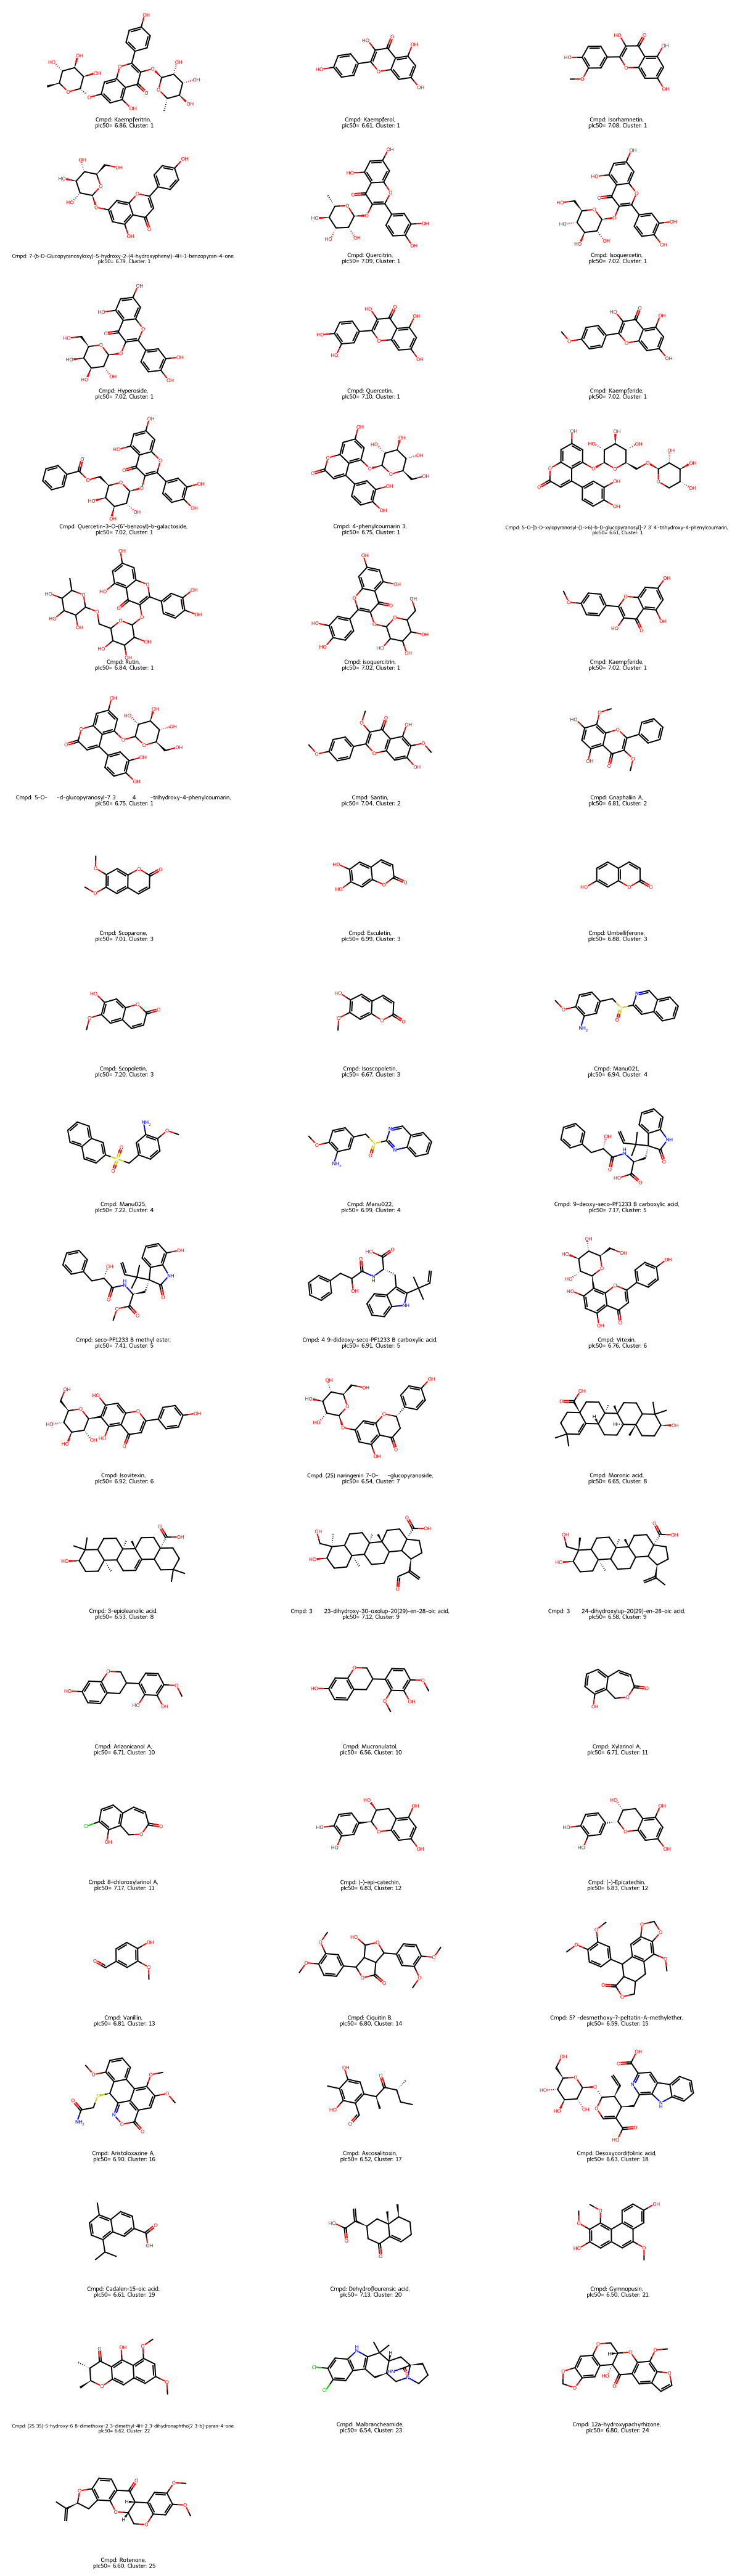

In [40]:
filtered_dataset2 = filtered_dataset1[filtered_dataset1['G'] != 'data']
Draw.MolsToGridImage([x for x in filtered_dataset2["Structure"]],#0:16],
                     maxMols=100,
                     legends=[f'Cmpd: {x},\n pIc50= {y:.2f}, Cluster: {z}' for x,y,z in zip(filtered_dataset2["Cmpd"],
                                                                                                 filtered_dataset2["Activity"],
                                                                                                 filtered_dataset2["Cluster_number"])],
                     subImgSize=(400,220), molsPerRow=3)

# Cluster de candidatos

In [41]:
dataset_final = filtered_dataset2.copy()

In [42]:
# Ordena los elementos de dataset_final de acuerdo a Cluster_number
dataset_final_sorted = dataset_final.sort_values(by='Cluster_number')
#dataset_final_sorted

In [43]:
# Get unique cluster numbers where the number of structures is >= 2
clusters = dataset_final.groupby('Cluster_number')['Structure'].count().reset_index()
# Filter clusters DataFrame instead of the list
clusters = clusters[clusters['Structure'] == 1]['Cluster_number'].tolist()

In [44]:
# Get unique cluster numbers where the number of structures is >= 2
clusters_to_process = dataset_final.groupby('Cluster_number')['Structure'].count().reset_index()
clusters_to_process = clusters_to_process[clusters_to_process['Structure'] >= 2]['Cluster_number'].tolist()

In [45]:
mcs_results = {}  # Store MCS results for each cluster

for cluster_number in clusters_to_process:
    filtered_df = dataset_final[dataset_final['Cluster_number'] == cluster_number]
    mcs_mol, _, _, success = find_mcs_multiple(filtered_df.SMILES)
    if success:
        mcs_results[cluster_number] = (mcs_mol, len(filtered_df)) # Store MCS and molecule count
    else:
        mcs_results[cluster_number] = (None, len(filtered_df)) # Store None and molecule count if MCS not found
        print(f"Could not find MCS for cluster {cluster_number}")

In [46]:
filtered_df = dataset_final[dataset_final['Cluster_number'].isin(clusters_to_process)]
#filtered_df

In [47]:
# prompt: con mcs_results has un dataframe donde tengas el objeto mol relacionado con sus cluster_number
mcs_results_df = pd.DataFrame(list(mcs_results.items()), columns=['Cluster_number', 'mol'])
#mcs_results_df

In [48]:
mcs_results_df = pd.DataFrame(list(mcs_results.items()), columns=['Cluster_number', 'mol_count'])
mcs_results_df[['mol', 'molecule_count']] = pd.DataFrame(mcs_results_df['mol_count'].tolist(), index= mcs_results_df.index)
mcs_results_df = mcs_results_df.drop('mol_count', axis=1)

In [49]:
# De dataset_cs toma los valores donde cluster_nuiber solo aparece una vez
cluster_counts = dataset_final['Cluster_number'].value_counts()
single_occurrence_clusters = cluster_counts[cluster_counts == 1].index
dataset_cs_filtered = dataset_cs[dataset_cs['Cluster_number'].isin(single_occurrence_clusters)]

In [50]:
# prompt: ordena  de manera crecienta con respecto a la columna Cluster_nummber a dataset_cs_filtered

# Sort the DataFrame by the 'Cluster_number' column in ascending order
dataset_cs_filtered = dataset_cs_filtered.sort_values('Cluster_number')
#dataset_cs_filtered

In [51]:
# Create a single list for legends
legends = []

# Add legends for mcs_results_df
legends.extend(['Cluster ID: ' + str(x) +
                ', freq: ' + str(y) + '\n' +
                'PIC50 '+'\n'
                'max : ' + str(round(z,2)) + ', min : ' + str(round(w,2))
                for x, y, z, w in zip(mcs_results_df.Cluster_number,
                                      mcs_results_df.molecule_count,
                                      dataset_final.groupby('Cluster_number')['Activity'].max(),
                                      dataset_final.groupby('Cluster_number')['Activity'].min())])

# Add legends for dataset_cs_filtered
legends.extend(['Cmpd: ' + str(x) + '\n'', pIC50: ' + str(round(y,2)) for x, y in zip(dataset_cs_filtered.Cmpd,
                                                                                dataset_cs_filtered.Activity)])

In [52]:
# Create a single list for legends
legends2 = []

# Add legends for mcs_results_df
legends2.extend(['Cluster ID: ' + str(x) +'\n'
                 'Cmpd: ' + str(y) + '\n'
                 'PMIC: '+ str(round(z,2))
                 for x, y,z in zip(filtered_df.Cluster_number,
                                   filtered_df.Cmpd,
                                   filtered_df.Activity)])

# Add legends for dataset_cs_filtered
legends2.extend(['Cmpd: ' + str(x) + '\n'
                 ', pMIC: ' + str(round(y,2))
                 for x, y in zip(dataset_cs_filtered.Cmpd,
                                 dataset_cs_filtered.Activity)])

#  Cuadrícula de candidatos con cluster

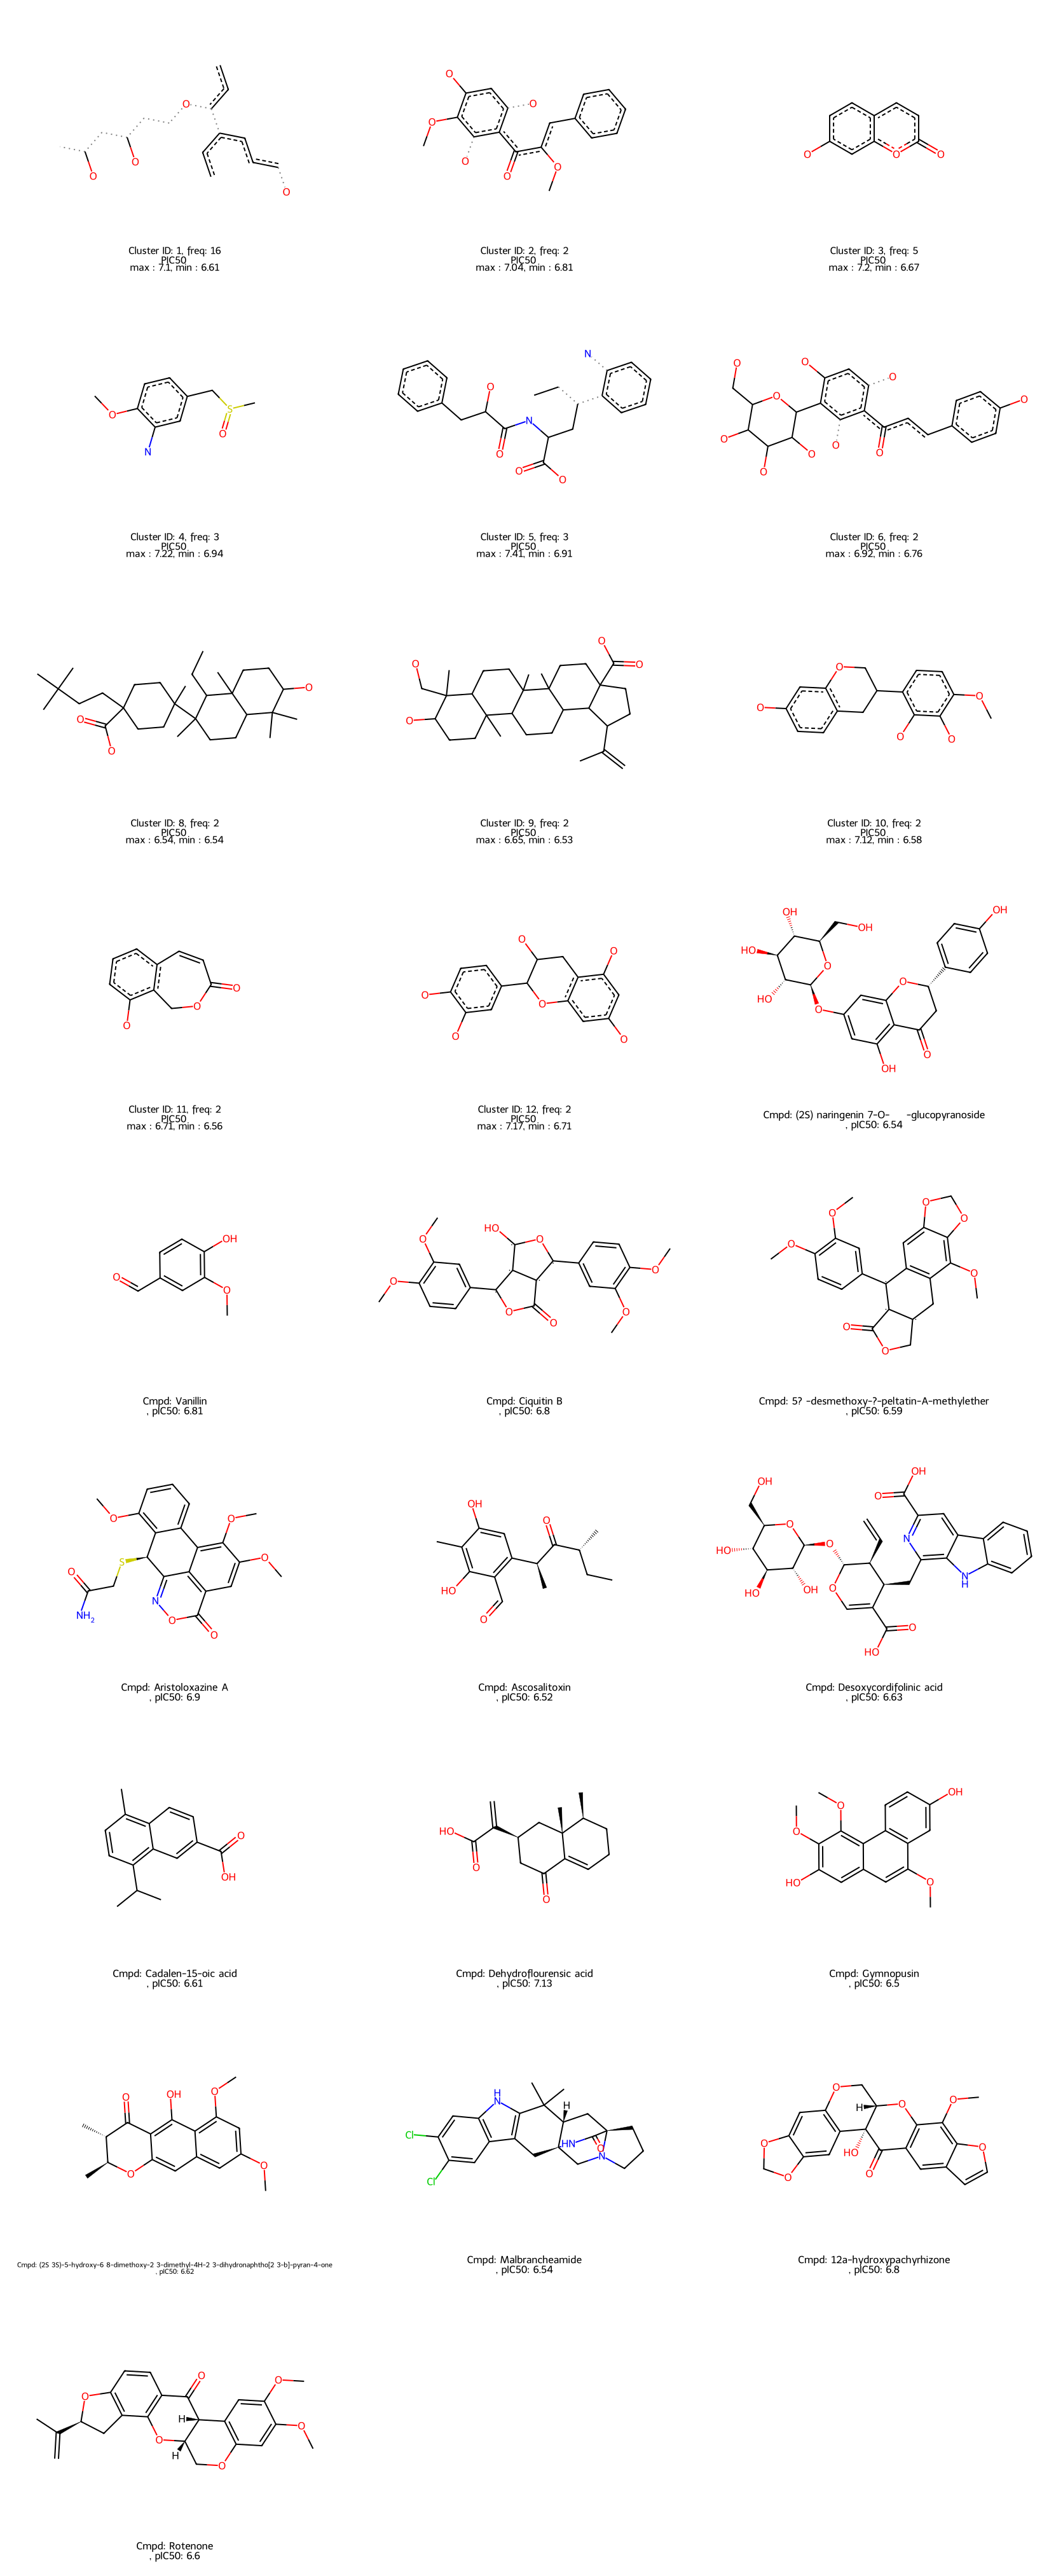

In [53]:
# Combina a y b
combined_image = Draw.MolsToGridImage(
    mols=[mol for mol in mcs_results_df.mol] + [x for x in dataset_cs_filtered["Structure"]],
    legends=legends,  # use the legends list created before
    maxMols=200, subImgSize=(550, 450), molsPerRow=3)
# Display the combined image
combined_image

# Ultimo vistazo

In [54]:
# @title
# Reset the index and create a new 'indice' column with the new index values
filtered_dataset1.reset_index(drop=True, inplace=True)
filtered_dataset1['indice'] = filtered_dataset1.index



In [55]:
# @title
img = Draw.MolsToGridImage([x for x in filtered_dataset1.Structure],
                                  legends=[f'Cmpd: {a}, \n pic50: {x:0.2f}, indice {y}' for a,x,y in zip(filtered_dataset1.Cmpd,filtered_dataset1.Activity, filtered_dataset1.indice)],
                                   maxMols=200,
                                   #highlightAtomLists=highlight_lists
                                   #highlightAtomLists=highlight_lists,
                                   subImgSize=(450,450))
img

In [56]:
# @title
# prompt: para los smiles de dataset_cs_sorted calculca los indices de tanimoto de manera matricial
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      # Calculate fingerprints for the molecules in dataset_cs_sorted
      fps = [AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=2048) for mol in filtered_dataset1["Structure"]]
      # Calculate the Tanimoto similarity matrix
      tanimoto_matrix = np.zeros((len(fps), len(fps)))
      for i in range(len(fps)):
        for j in range(i, len(fps)):
          # Calculate only upper triangle, it's symmetric
          tanimoto_matrix[i, j] = DataStructs.CosineSimilarity(fps[i], fps[j])
          #tanimoto_matrix[i, j] = DataStructs.TanimotoSimilarity(fps[i], fps[j])
          tanimoto_matrix[j, i] = tanimoto_matrix[i, j] # Fill the lower triangle
          # Assuming 'tanimoto_matrix' is already calculated as in your original code
      pbar.update(100)

  0%|          | 0/100 [00:00<?, ?it/s]

In [57]:
# @title
fig = px.imshow(tanimoto_matrix,
                labels=dict(x="Molecule Index", y="Molecule Index", color="Tanimoto Similarity"),
                title="Tanimoto Similarity Matrix Heatmap 2",
                color_continuous_scale='Blues', # You can change the color scale
                width=1000, height=800)

fig.update_xaxes(side="bottom")  # Move x-axis label to the bottom
fig.add_shape(type="line", x0=41, y0=0, x1=41, y1=len(tanimoto_matrix), line=dict(color="Green", width=2, dash="dashdot"))
fig.add_shape(type="line", x0=0, y0=41, x1=len(tanimoto_matrix), y1=41, line=dict(color="Green", width=2, dash="dashdot"))
fig.show()

Análisis de la matriz

Cmpd: 4. 12c
cluster ID: 3
pIC50: 7.036212173
G: data
Cmpd: 4. 12c


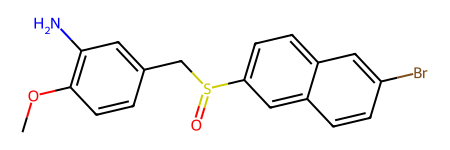

In [58]:
idx=26
print ('Cmpd: '+  str(filtered_dataset1["Cmpd"][idx]))
print('cluster ID: '+ str(filtered_dataset1["Cluster_number"][idx]))
print('pIC50: ' + str(filtered_dataset1["Activity"][idx]))
print('G: '+ str(filtered_dataset1["G"][idx]))
print('Cmpd: '+ str(filtered_dataset1["Cmpd"][idx]))
m1 = filtered_dataset1["Structure"][idx]
m1

Cmpd: Arizonicanol A
sub_idx: 78
cluster ID: 10
pIC50: 6.713756209938554
G: xplor


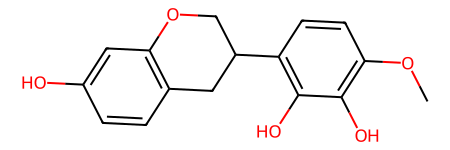

In [59]:
idx =78
print ('Cmpd: '+  str(filtered_dataset1["Cmpd"][idx]))
print ('sub_idx: '+ str(idx))
print('cluster ID: '+ str(filtered_dataset1["Cluster_number"][idx]))
print('pIC50: ' + str(filtered_dataset1["Activity"][idx]))
print('G: '+ str(filtered_dataset1["G"][idx]))
m2 = filtered_dataset1["Structure"][idx]
m2

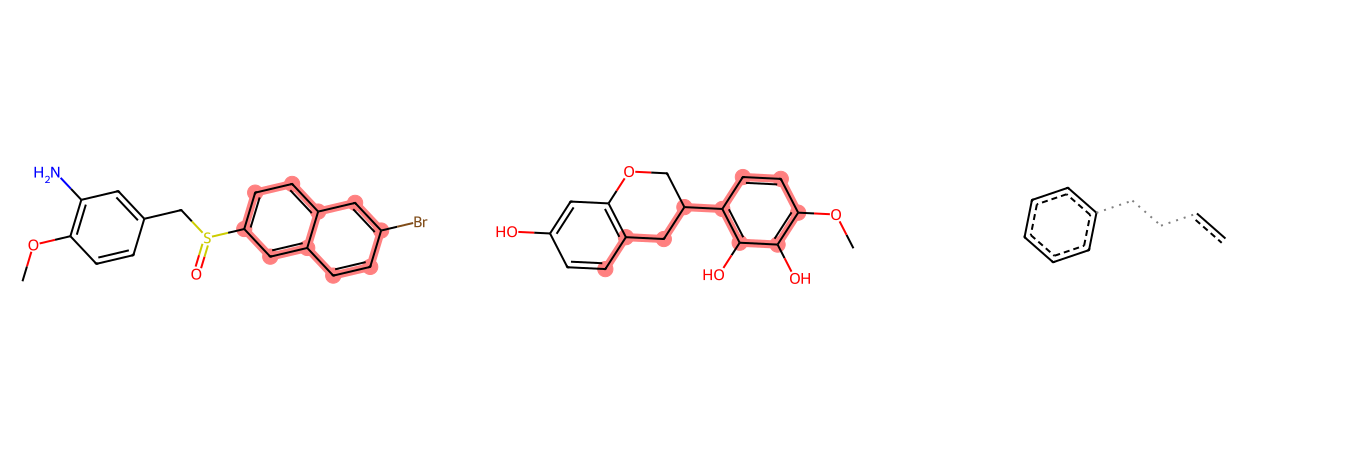

In [60]:
comparison_image_ = find_mcs_and_draw_2(m1, m2)
comparison_image_

In [61]:
idx = 95
# Extract Tanimoto similarities for compound 10
compound_idx_similarities = tanimoto_matrix[idx]

# Create a DataFrame for plotting
similarity_df = pd.DataFrame({'Compound': range(len(compound_idx_similarities)),'Tanimoto Similarity': compound_idx_similarities})

# Add the 'G' column from combined_df_1 to similarity_df
similarity_df['G'] = filtered_dataset1['G']

fig = px.bar(similarity_df, x='Compound', y='Tanimoto Similarity',
             labels={'Compound': 'Compound Index', 'Tanimoto Similarity': 'Tanimoto Similarity to Compound idx'},
             title=f'Tanimoto Similarity of Compound {idx} to Other Compounds',
             color='G') # color is now based on the 'G' column
fig.show()